# What drives lab turnaround-time breaches?

A diagnostic lab promises each result within a target time (the **turnaround time**, or TAT). A *breach* is a result verified after its target. This notebook works through six months of test-level records from a nine-site lab network and asks:

1. Did the process change introduced in week 9 actually improve compliance, or would it have improved anyway?
2. Holding everything else equal, what makes a test more likely to breach?
3. Where would fixing staffing remove the most breaches?
4. When tests breach, by how much?

**The data is synthetic.** It comes from `generator/generate_lab_data.py`, which simulates how samples move through a lab (opening hours, couriers, batch runs, queues, instrument downtime, staffing). I built it to mirror the structure of real LIS exports I work with, without using any real patient, site or volume data. The methods are what matter here: they are the same ones I would run on the real thing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, BLUE_LIGHT, RED = "#2a78d6", "#9ec5f4", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "Segoe UI", "font.size": 10, "text.color": INK,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "figure.dpi": 110, "savefig.dpi": 150,
})
FIG = "figures/"


## 1. Load and check the data

In [2]:
raw = pd.read_csv("data/tests.csv", parse_dates=["entered_at", "received_at", "verified_at"])
print(f"{len(raw):,} tests, {raw.req_number.nunique():,} requisitions, "
      f"{raw.entered_at.min():%d %b %Y} to {raw.entered_at.max():%d %b %Y}")

checks = pd.Series({
    "Never verified (no TAT)":            raw.verified_at.isna().sum(),
    "No target (test not in catalogue)":  raw.target_hours.isna().sum(),
    "Zero TAT (verified the minute it was entered)": (raw.tat_hours == 0).sum(),
    "No department":                      raw.department.isna().sum(),
})
checks.to_frame("rows")

111,398 tests, 48,462 requisitions, 06 Jan 2025 to 06 Jul 2025


,rows
Never verified (no TAT),868
No target (test not in catalogue),242
Zero TAT (verified the minute it was entered),432
No department,337


Unverified tests and tests without a target can't be scored, so they're excluded from compliance (not counted as failures). Zero-TAT results are almost always data-entry artefacts, so they're excluded too: counting them as passes would flatter the numbers. Missing departments are kept as "Unassigned".

I also add the **daily workload** of the performing site (tests entered that day), because queueing is the obvious mechanism behind many breaches.

In [3]:
df = raw[raw.tat_hours.notna() & raw.target_hours.notna() & (raw.tat_hours > 0)].copy()
df["department"] = df.department.fillna("Unassigned")
df["breached"] = df.breached.astype(int)
df["post_launch"] = (df.week >= 9).astype(int)
df["weekend"] = df.weekday.isin(["Saturday", "Sunday"]).astype(int)
daily = df.groupby(["perf_site", "entry_date"]).size().rename("site_daily_tests")
df = df.join(daily, on=["perf_site", "entry_date"])
df["load_100"] = df.site_daily_tests / 100   # so the odds ratio reads "per extra 100 tests"

print(f"{len(df):,} tests scored ({len(raw) - len(df):,} excluded)")
print(f"Overall compliance: {100 * (1 - df.breached.mean()):.1f}%")

109,861 tests scored (1,537 excluded)
Overall compliance: 63.2%


## 2. Did the week-9 change work?

Weeks 1-8 average: 52.6%   Weeks 17-26 average: 71.9%


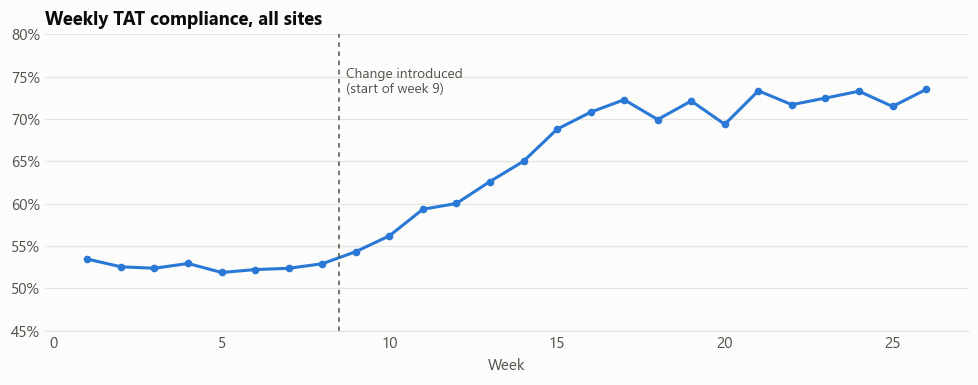

In [4]:
weekly = (df.groupby("week")
            .agg(tests=("breached", "size"), compliance=("breached", lambda b: 100 * (1 - b.mean())))
            .reset_index())
before = weekly[weekly.week < 9].compliance.mean()
after = weekly[weekly.week >= 17].compliance.mean()
print(f"Weeks 1-8 average: {before:.1f}%   Weeks 17-26 average: {after:.1f}%")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(weekly.week, weekly.compliance, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(8.5, color=MUTED, lw=1, ls=(0, (3, 3)))
ax.text(8.7, 76, "Change introduced\n(start of week 9)", color=MUTED, fontsize=9, va="top")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.set_ylim(45, 80); ax.set_xlabel("Week"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("Weekly TAT compliance, all sites", loc="left", fontsize=12, weight="bold")
fig.tight_layout(); fig.savefig(FIG + "weekly_compliance.png")

A before/after average can't tell a real effect from a trend that was already under way. **Segmented regression** (interrupted time series) separates the two: it fits the pre-launch trend, then asks whether the level and slope changed after week 9. Weekly points are autocorrelated, so standard errors use Newey-West (HAC) with a 2-week lag.

In [5]:
weekly["post"] = (weekly.week >= 9).astype(int)
weekly["weeks_since"] = np.maximum(0, weekly.week - 8)
its = smf.ols("compliance ~ week + post + weeks_since", data=weekly).fit(
    cov_type="HAC", cov_kwds={"maxlags": 2})
its_table = pd.DataFrame({"estimate": its.params, "ci_low": its.conf_int()[0],
                          "ci_high": its.conf_int()[1], "p_value": its.pvalues}).round(3)
its_table

,estimate,ci_low,ci_high,p_value
Intercept,52.902,52.350,53.453,0.000
week,-0.074,-0.198,0.049,0.236
post,5.289,0.782,9.795,0.021
weeks_since,1.125,0.777,1.472,0.000


In [6]:
pre_slope, slope_change = its.params["week"], its.params["weeks_since"]
print(f"Pre-launch trend: {pre_slope:+.2f} points/week (p = {its.pvalues['week']:.2f})")
print(f"Change in trend after launch: {slope_change:+.2f} points/week "
      f"(95% CI {its.conf_int().loc['weeks_since', 0]:+.2f} to {its.conf_int().loc['weeks_since', 1]:+.2f})")
counterfactual = its.params["Intercept"] + pre_slope * 26
print(f"Week 26: observed {weekly.compliance.iloc[-1]:.1f}%, "
      f"projected from the old trend {counterfactual:.1f}%")

Pre-launch trend: -0.07 points/week (p = 0.24)
Change in trend after launch: +1.12 points/week (95% CI +0.78 to +1.47)
Week 26: observed 73.5%, projected from the old trend 51.0%


## 3. What makes a test more likely to breach?

Raw breach rates by site or shift are confounded: hub sites run more long-target tests, outside-hours samples skew to certain sites, and so on. A **logistic regression** estimates each factor's effect with the others held constant. Reference levels are the largest site (Central), Haematology, the morning shift, a weekday, a local (not referred) sample, and the pre-launch period.

In [7]:
model = smf.logit(
    "breached ~ C(perf_site, Treatment('Central')) + C(department, Treatment('Haematology'))"
    " + C(shift, Treatment('Morning (8am-2pm)')) + weekend + is_shipped + load_100 + post_launch",
    data=df).fit(disp=False)

ors = pd.DataFrame({"odds_ratio": np.exp(model.params), "ci_low": np.exp(model.conf_int()[0]),
                    "ci_high": np.exp(model.conf_int()[1]), "p_value": model.pvalues})
ors.index = (ors.index.str.replace(r"C\((\w+), Treatment\('.*?'\)\)\[T\.(.*)\]", r"\1: \2", regex=True)
                        .str.replace("is_shipped[T.True]", "Referred to another site", regex=False)
                        .str.replace("weekend", "Weekend", regex=False)
                        .str.replace("load_100", "Site workload (+100 tests/day)", regex=False)
                        .str.replace("post_launch", "After the week-9 change", regex=False)
                        .str.replace("perf_site: ", "Site: ", regex=False)
                        .str.replace("department: ", "Department: ", regex=False)
                        .str.replace("shift: ", "Entered: ", regex=False))
ors = ors.drop("Intercept").round(3)
print(f"n = {int(model.nobs):,}   pseudo R-squared = {model.prsquared:.3f}")
ors.sort_values("odds_ratio", ascending=False)

n = 109,861   pseudo R-squared = 0.092


,odds_ratio,ci_low,ci_high,p_value
Site: Riverside,10.024,9.004,11.159,0.0
Site: Lakeside,9.518,8.482,10.681,0.0
Site: Westbrook,3.697,3.262,4.191,0.0
Site: Eastfield,3.518,3.148,3.932,0.0
Site: Hilltop,3.396,3.018,3.823,0.0
Site: Parkview,3.279,2.881,3.733,0.0
Referred to another site,2.747,2.609,2.893,0.0
Site: Northgate,2.218,2.000,2.458,0.0
Weekend,1.977,1.867,2.093,0.0
Site: Harbour,1.406,1.331,1.484,0.0


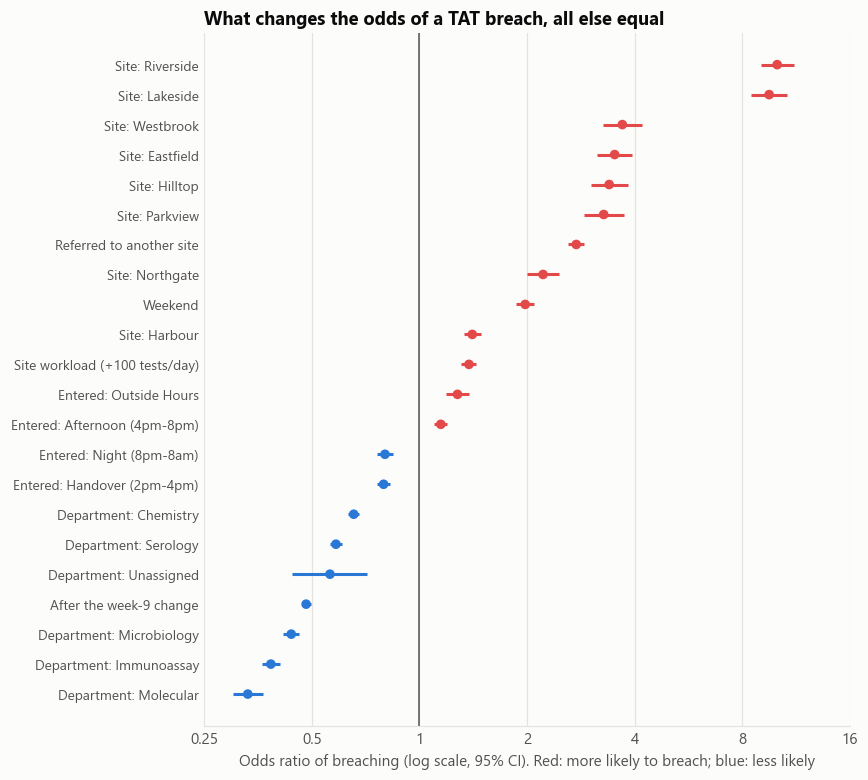

In [8]:
plot = ors.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 7.2))
y = np.arange(len(plot))
colors = [RED if lo > 1 else (BLUE if hi < 1 else MUTED) for lo, hi in zip(plot.ci_low, plot.ci_high)]
ax.hlines(y, plot.ci_low, plot.ci_high, color=colors, lw=2)
ax.scatter(plot.odds_ratio, y, color=colors, s=28, zorder=3)
ax.axvline(1, color=MUTED, lw=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 16]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8", "16"]); ax.minorticks_off()
ax.set_yticks(y); ax.set_yticklabels(plot.index, fontsize=9); ax.tick_params(length=0)
ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
ax.set_xlabel("Odds ratio of breaching (log scale, 95% CI). Red: more likely to breach; blue: less likely")
ax.set_title("What changes the odds of a TAT breach, all else equal", loc="left", fontsize=12, weight="bold")
fig.tight_layout(); fig.savefig(FIG + "breach_odds_ratios.png")

**Reading the odds ratios.** Two short-staffed sites stand out: a test performed at Riverside or Lakeside has roughly ten times the odds of breaching as the same test at Central. Beyond site, a sample referred to another site has about 2.7 times the odds, weekends about 2, and every extra 100 tests a site handles in a day raises the odds by about 40%. Samples entered outside opening hours wait for the site to open and are the worst shift.

Night and handover entries come out *less* likely to breach than morning ones. That isn't a sign handover is harmless: shift here is when the sample was **entered**, and handover delays hit work being **finished** between 2pm and 4pm, which mostly started in the morning. Measuring completion shift would need the verification timestamp split by bench, which a weekly export doesn't carry.

## 4. Where would fixing staffing remove the most breaches?

In [9]:
# Counterfactual: predict breaches if Riverside and Lakeside performed like a fully staffed
# site of similar size (Eastfield), keeping everything else about their tests the same.
short = df.perf_site.isin(["Riverside", "Lakeside"])
cf = df[short].copy()
actual = model.predict(cf).sum()
cf["perf_site"] = "Eastfield"
fixed = model.predict(cf).sum()
weeks = df.week.nunique()
print(f"Riverside + Lakeside: {short.sum():,} tests, {df[short].breached.sum():,} breaches "
      f"({100 * df[short].breached.mean():.1f}%)")
print(f"Model-expected breaches: {actual:,.0f}  ->  {fixed:,.0f} if staffed like Eastfield")
print(f"About {(actual - fixed) / weeks:,.0f} fewer breaches per week, "
      f"{100 * (actual - fixed) / df.breached.sum():.1f}% of all network breaches")

Riverside + Lakeside: 15,162 tests, 10,026 breaches (66.1%)
Model-expected breaches: 10,026  ->  6,422 if staffed like Eastfield
About 139 fewer breaches per week, 8.9% of all network breaches


In [10]:
site = (df.groupby("perf_site")
          .agg(tests=("breached", "size"), breaches=("breached", "sum"))
          .assign(rate=lambda t: 100 * t.breaches / t.tests,
                  share_of_breaches=lambda t: 100 * t.breaches / t.breaches.sum())
          .sort_values("rate", ascending=False))
site.round(1)

,tests,breaches,rate,share_of_breaches
perf_site,,,,
Riverside,8559,5723,66.9,14.1
Lakeside,6603,4303,65.2,10.6
Eastfield,7211,3037,42.1,7.5
Westbrook,4434,1867,42.1,4.6
Hilltop,5614,2295,40.9,5.7
Parkview,3837,1494,38.9,3.7
Northgate,9359,3001,32.1,7.4
Harbour,25371,7485,29.5,18.5
Central,38873,11265,29.0,27.8


## 5. When tests breach, by how much?

The same four bands the TAT platform uses: **marginal** (within 30 minutes or 15% of target), **moderate** (up to 3 hours over), **severe** (3–12 hours) and **critical** (over 12 hours). They call for different responses: marginal breaches are process tightening, critical ones are individual incidents.

In [11]:
def band(over_h, target_h):
    over_m, rel = over_h * 60, over_h / target_h
    if over_m <= 30 or rel <= 0.15:
        return "Marginal"
    if over_m <= 180:
        return "Moderate"
    if over_m <= 720:
        return "Severe"
    return "Critical"

late = df[df.breached == 1].copy()
late["over_h"] = late.tat_hours - late.target_hours
late["band"] = [band(o, t) for o, t in zip(late.over_h, late.target_hours)]
order = ["Marginal", "Moderate", "Severe", "Critical"]
bands = (late.groupby(["post_launch", "band"]).size().unstack(0)
             .reindex(order).rename(columns={0: "before", 1: "after"}))
bands_pct = (100 * bands / bands.sum()).round(1)
bands_pct

post_launch,before,after
band,,
Marginal,19.5,25.8
Moderate,30.4,32.4
Severe,32.3,26.0
Critical,17.8,15.8


In [12]:
# Is the shift in severity mix after the launch more than chance?
chi2, p, dof, _ = stats.chi2_contingency(bands.values)
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.2g}")
outside = df[df["shift"] == "Outside Hours"]
print(f"Outside-hours samples: {100 * outside.breached.mean():.1f}% breach, "
      f"median wait of {(late[late['shift'] == 'Outside Hours'].over_h.median()):.1f} h past target when late")

Chi-square = 329.6, df = 3, p = 3.8e-71
Outside-hours samples: 53.2% breach, median wait of 3.6 h past target when late


## 6. What I would tell the lab manager

The numbers below are printed from the analysis above, so they always match it.

In [13]:
drivers = ors.loc[["Referred to another site", "Weekend", "Site workload (+100 tests/day)", "Entered: Outside Hours"]]
serious_before = bands_pct.loc[["Severe", "Critical"], "before"].sum()
serious_after = bands_pct.loc[["Severe", "Critical"], "after"].sum()
print(f"1. The week-9 change worked beyond the existing trend: compliance went from {before:.0f}% to {after:.0f}%,")
print(f"   and the trend steepened by {slope_change:+.2f} points a week (it was flat before, {pre_slope:+.2f}).")
print(f"2. Riverside and Lakeside are the biggest single problem: about 10x the odds of a breach of Central,")
print(f"   and {site.loc[['Riverside', 'Lakeside'], 'share_of_breaches'].sum():.0f}% of all breaches from "
      f"{100 * short.mean():.0f}% of tests.")
print("3. Across all sites, the other drivers are:")
for name, r in drivers.iterrows():
    print(f"   - {name}: odds x{r.odds_ratio:.2f} (95% CI {r.ci_low:.2f}-{r.ci_high:.2f})")
print(f"4. Staffing those two sites like Eastfield would remove about {(actual - fixed) / weeks:,.0f} breaches a week,")
print(f"   {100 * (actual - fixed) / df.breached.sum():.0f}% of the network total.")
print(f"5. Breaches also got less serious: severe and critical fell from {serious_before:.0f}% to {serious_after:.0f}% "
      f"of breaches (chi-square p = {p:.1g}).")

1. The week-9 change worked beyond the existing trend: compliance went from 53% to 72%,
   and the trend steepened by +1.12 points a week (it was flat before, -0.07).
2. Riverside and Lakeside are the biggest single problem: about 10x the odds of a breach of Central,
   and 25% of all breaches from 14% of tests.
3. Across all sites, the other drivers are:
   - Referred to another site: odds x2.75 (95% CI 2.61-2.89)
   - Weekend: odds x1.98 (95% CI 1.87-2.09)
   - Site workload (+100 tests/day): odds x1.38 (95% CI 1.31-1.44)
   - Entered: Outside Hours: odds x1.28 (95% CI 1.19-1.38)
4. Staffing those two sites like Eastfield would remove about 139 breaches a week,
   9% of the network total.
5. Breaches also got less serious: severe and critical fell from 50% to 42% of breaches (chi-square p = 4e-71).


**Limits.** The data is simulated, so effect sizes reflect the generator's assumptions, not a real lab. The model is associational: it can't separate staffing from anything else that differs between sites. The week-9 analysis has no control group, so a network-wide shock at the same time would look like an effect. On real data I'd add site-level random effects and check calibration before using the counterfactual for planning.